In [1]:
# This import is necessary to run the code cell-by-cell
try:
    from lab04_solution import *

    print("lab04_solution is being used")

except ImportError:
    from lab04 import *

    print("lab04 is being used")
import matplotlib.pyplot as plt
op = Lab04_op()

lab04_solution is being used


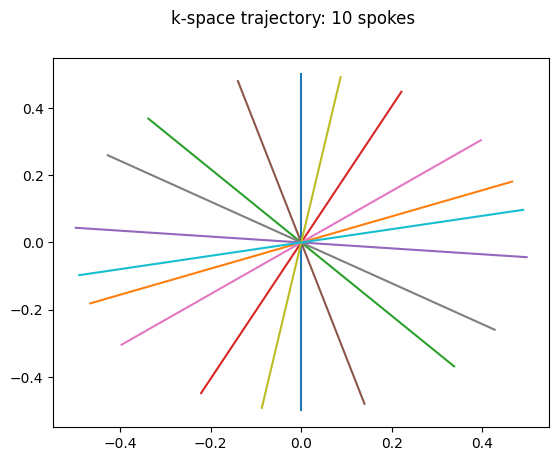

In [2]:
k_radial = op.load_kdata()
traj = op.get_traj(k_radial)
utils.plot_spokes(traj, 10)

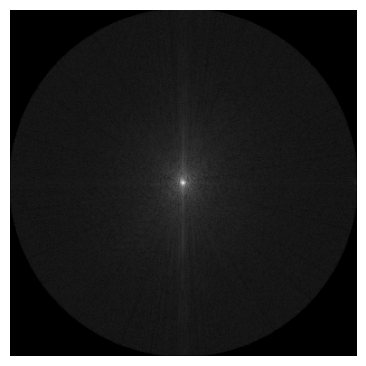

In [3]:
# gridded k-space
k_cart = op.grid_radial(k_radial, traj)
utils.imshow([k_cart], norm=0.2)

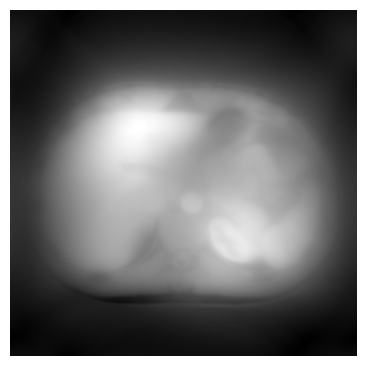

In [4]:
# gridded k-space reconstruction
recon = utils.ifft2c(k_cart)
utils.imshow([recon])

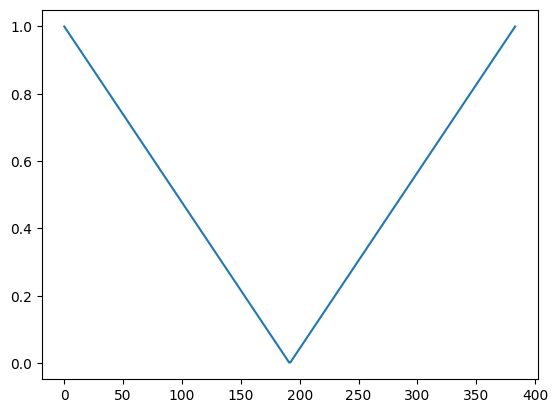

In [5]:
# ramp filter
ramp = op.get_ramp(k_radial)
plt.plot(ramp)

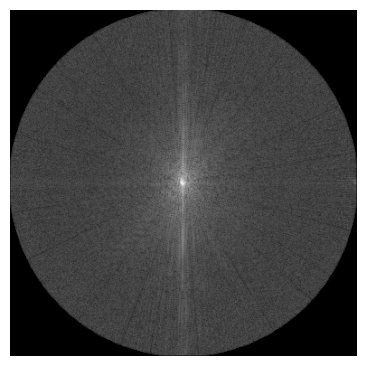

In [6]:
# gridded k-space with ramp filter
k_cart_ds = op.grid_radial_ds(k_radial, traj)
utils.imshow([k_cart_ds], norm=0.2)

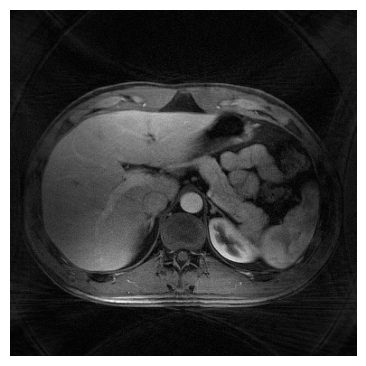

In [7]:
# gridded k-space with ramp filter, reconstruction
recon_ds = utils.ifft2c(k_cart_ds)
utils.imshow([recon_ds])

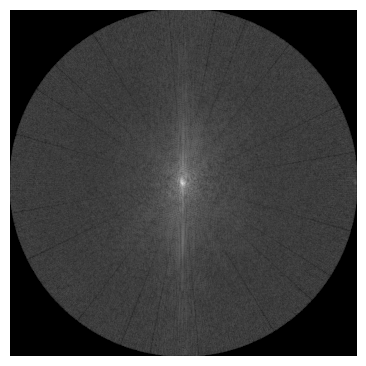

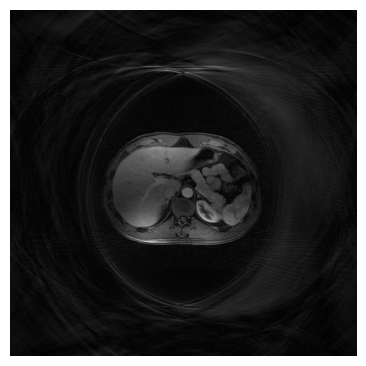

In [8]:
# oversampled k-space and reconstruction
k_cart_os = op.grid_radial_ds_os(k_radial, traj, 2)
recon_os = utils.ifft2c(k_cart_os)
utils.imshow([k_cart_os], norm=0.2)
utils.imshow([recon_os])

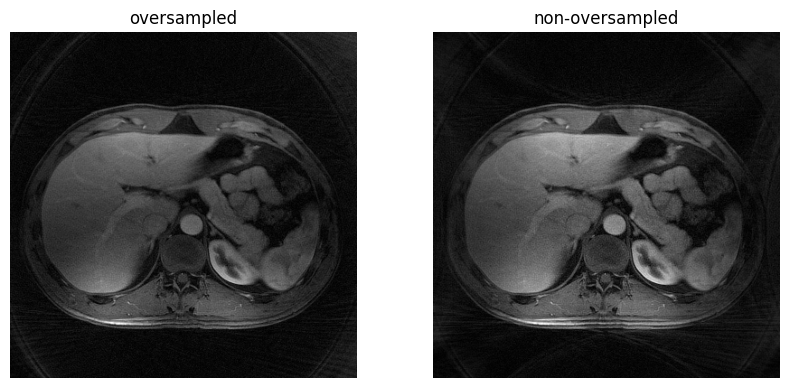

In [9]:
# compare reconstructions with and without oversampling
recon_crop = op.center_crop_2d(recon_os, (384, 384))
utils.imshow([recon_crop, recon_ds], titles=["oversampled", "non-oversampled"])

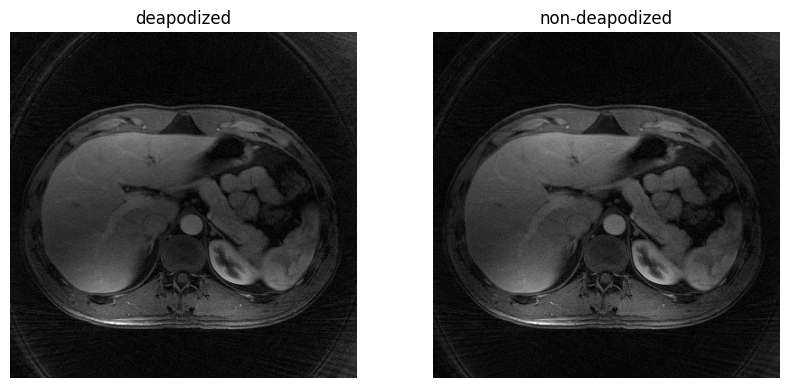

In [10]:
# deapodized/non-deapodized reconstruction
recon_deapo = op.deapodization(k_radial, traj, 2)
utils.imshow([recon_deapo, recon_crop], titles=["deapodized", "non-deapodized"])

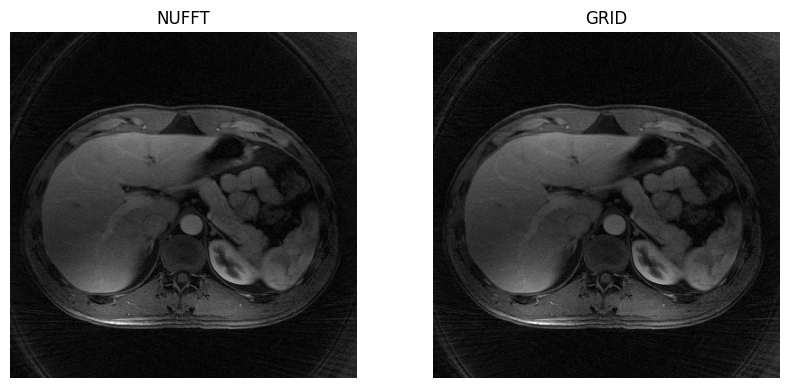

In [11]:
# compare all the reconstructions
recon_nufft = op.nufft_recon(k_radial, (384, 384))
utils.imshow([recon_nufft, recon_deapo], titles=["NUFFT", "GRID"])